In [18]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [19]:
words = open('C:/Users/Kush Viradiya/andrej karapathy/makemore/names.txt','r').read().splitlines()
words[:0]

[]

In [20]:
len(words)

32033

In [21]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.']=0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [143]:
block_size =3
X,Y = [],[]
for w in words:
    #print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        #print(''.join(itos[i]for i in context),'--->',itos[ix])
        context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)

In [144]:
X.shape , X.dtype , Y.shape , Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [32]:
X

tensor([[ 0,  0,  0],
        [ 0,  0,  5],
        [ 0,  5, 13],
        [ 5, 13, 13],
        [13, 13,  1],
        [ 0,  0,  0],
        [ 0,  0, 15],
        [ 0, 15, 12],
        [15, 12,  9],
        [12,  9, 22],
        [ 9, 22,  9],
        [22,  9,  1],
        [ 0,  0,  0],
        [ 0,  0,  1],
        [ 0,  1, 22],
        [ 1, 22,  1],
        [ 0,  0,  0],
        [ 0,  0,  9],
        [ 0,  9, 19],
        [ 9, 19,  1],
        [19,  1,  2],
        [ 1,  2,  5],
        [ 2,  5, 12],
        [ 5, 12, 12],
        [12, 12,  1],
        [ 0,  0,  0],
        [ 0,  0, 19],
        [ 0, 19, 15],
        [19, 15, 16],
        [15, 16,  8],
        [16,  8,  9],
        [ 8,  9,  1]])

In [24]:
C = torch.randn((27,2))
C

tensor([[-0.3762,  0.2010],
        [ 0.0487, -0.1474],
        [ 0.2433,  0.6356],
        [ 0.3463,  0.1188],
        [ 0.7715,  1.2241],
        [-0.9427,  0.0955],
        [ 0.0736, -1.4601],
        [-1.2390, -0.4689],
        [ 1.0851,  0.1603],
        [-1.3871, -0.2413],
        [ 0.1207, -0.6893],
        [ 0.7771, -0.3282],
        [ 0.6970,  0.3334],
        [-1.4786,  1.3733],
        [ 1.2359,  0.7055],
        [-1.3422,  0.1300],
        [ 0.4724,  0.0828],
        [-0.9752, -2.7544],
        [ 0.5681,  0.7650],
        [ 0.6372, -0.9062],
        [-0.6182, -0.0556],
        [ 0.4362, -0.5912],
        [ 0.4484,  1.6664],
        [ 2.0483,  0.0531],
        [-0.3302, -1.8162],
        [-0.1427, -1.0012],
        [ 0.4467,  1.0235]])

In [25]:
 C[5]

tensor([-0.9427,  0.0955])

In [26]:
#one hot way of indexing the matrix
#F.one_hot(torch.tensor(5),num_classes=27).float() @ C

In [27]:
 C[torch.tensor([5,6,7,7,7])]

tensor([[-0.9427,  0.0955],
        [ 0.0736, -1.4601],
        [-1.2390, -0.4689],
        [-1.2390, -0.4689],
        [-1.2390, -0.4689]])

In [33]:
C[X]

tensor([[[-0.3762,  0.2010],
         [-0.3762,  0.2010],
         [-0.3762,  0.2010]],

        [[-0.3762,  0.2010],
         [-0.3762,  0.2010],
         [-0.9427,  0.0955]],

        [[-0.3762,  0.2010],
         [-0.9427,  0.0955],
         [-1.4786,  1.3733]],

        [[-0.9427,  0.0955],
         [-1.4786,  1.3733],
         [-1.4786,  1.3733]],

        [[-1.4786,  1.3733],
         [-1.4786,  1.3733],
         [ 0.0487, -0.1474]],

        [[-0.3762,  0.2010],
         [-0.3762,  0.2010],
         [-0.3762,  0.2010]],

        [[-0.3762,  0.2010],
         [-0.3762,  0.2010],
         [-1.3422,  0.1300]],

        [[-0.3762,  0.2010],
         [-1.3422,  0.1300],
         [ 0.6970,  0.3334]],

        [[-1.3422,  0.1300],
         [ 0.6970,  0.3334],
         [-1.3871, -0.2413]],

        [[ 0.6970,  0.3334],
         [-1.3871, -0.2413],
         [ 0.4484,  1.6664]],

        [[-1.3871, -0.2413],
         [ 0.4484,  1.6664],
         [-1.3871, -0.2413]],

        [[ 0.4484,  1

In [29]:
C[X].shape

torch.Size([32, 3, 2])

In [30]:
X[13,2]

tensor(1)

In [31]:
C[X][13,2]

tensor([ 0.0487, -0.1474])

In [40]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [41]:
W1 = torch.randn((6,100))
b1 = torch.randn(100)

In [42]:
emb@W1 + b1

RuntimeError: mat1 and mat2 shapes cannot be multiplied (96x2 and 6x100)

In [58]:
torch.cat([emb[:,0,:], emb[:,1,:] , emb[:,2,:]],1).shape

torch.Size([32, 6])

In [59]:
#the code wont work for different nlock sizes , 
#so it is not a good implementation to directly concat.
#torch.cat([emb[:,0,:], emb[:,1,:] , emb[:,2,:]],1)

tensor([[-0.3762,  0.2010, -0.3762,  0.2010, -0.3762,  0.2010],
        [-0.3762,  0.2010, -0.3762,  0.2010, -0.9427,  0.0955],
        [-0.3762,  0.2010, -0.9427,  0.0955, -1.4786,  1.3733],
        [-0.9427,  0.0955, -1.4786,  1.3733, -1.4786,  1.3733],
        [-1.4786,  1.3733, -1.4786,  1.3733,  0.0487, -0.1474],
        [-0.3762,  0.2010, -0.3762,  0.2010, -0.3762,  0.2010],
        [-0.3762,  0.2010, -0.3762,  0.2010, -1.3422,  0.1300],
        [-0.3762,  0.2010, -1.3422,  0.1300,  0.6970,  0.3334],
        [-1.3422,  0.1300,  0.6970,  0.3334, -1.3871, -0.2413],
        [ 0.6970,  0.3334, -1.3871, -0.2413,  0.4484,  1.6664],
        [-1.3871, -0.2413,  0.4484,  1.6664, -1.3871, -0.2413],
        [ 0.4484,  1.6664, -1.3871, -0.2413,  0.0487, -0.1474],
        [-0.3762,  0.2010, -0.3762,  0.2010, -0.3762,  0.2010],
        [-0.3762,  0.2010, -0.3762,  0.2010,  0.0487, -0.1474],
        [-0.3762,  0.2010,  0.0487, -0.1474,  0.4484,  1.6664],
        [ 0.0487, -0.1474,  0.4484,  1.6

In [62]:
#inefficient and creates extra memory requirements
#torch.cat(torch.unbind(emb,1),1)

tensor([[-0.3762,  0.2010, -0.3762,  0.2010, -0.3762,  0.2010],
        [-0.3762,  0.2010, -0.3762,  0.2010, -0.9427,  0.0955],
        [-0.3762,  0.2010, -0.9427,  0.0955, -1.4786,  1.3733],
        [-0.9427,  0.0955, -1.4786,  1.3733, -1.4786,  1.3733],
        [-1.4786,  1.3733, -1.4786,  1.3733,  0.0487, -0.1474],
        [-0.3762,  0.2010, -0.3762,  0.2010, -0.3762,  0.2010],
        [-0.3762,  0.2010, -0.3762,  0.2010, -1.3422,  0.1300],
        [-0.3762,  0.2010, -1.3422,  0.1300,  0.6970,  0.3334],
        [-1.3422,  0.1300,  0.6970,  0.3334, -1.3871, -0.2413],
        [ 0.6970,  0.3334, -1.3871, -0.2413,  0.4484,  1.6664],
        [-1.3871, -0.2413,  0.4484,  1.6664, -1.3871, -0.2413],
        [ 0.4484,  1.6664, -1.3871, -0.2413,  0.0487, -0.1474],
        [-0.3762,  0.2010, -0.3762,  0.2010, -0.3762,  0.2010],
        [-0.3762,  0.2010, -0.3762,  0.2010,  0.0487, -0.1474],
        [-0.3762,  0.2010,  0.0487, -0.1474,  0.4484,  1.6664],
        [ 0.0487, -0.1474,  0.4484,  1.6

In [65]:
a = torch.arange(18)
a

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])

In [66]:
a.shape

torch.Size([18])

In [72]:
a.view(3,3,2)

tensor([[[ 0,  1],
         [ 2,  3],
         [ 4,  5]],

        [[ 6,  7],
         [ 8,  9],
         [10, 11]],

        [[12, 13],
         [14, 15],
         [16, 17]]])

In [80]:
a.storage()

 0
 1
 2
 3
 4
 5
 6
 7
 8
 9
 10
 11
 12
 13
 14
 15
 16
 17
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 18]

In [81]:
emb.shape

torch.Size([32, 3, 2])

In [82]:
emb.view(32,6)

tensor([[-0.3762,  0.2010, -0.3762,  0.2010, -0.3762,  0.2010],
        [-0.3762,  0.2010, -0.3762,  0.2010, -0.9427,  0.0955],
        [-0.3762,  0.2010, -0.9427,  0.0955, -1.4786,  1.3733],
        [-0.9427,  0.0955, -1.4786,  1.3733, -1.4786,  1.3733],
        [-1.4786,  1.3733, -1.4786,  1.3733,  0.0487, -0.1474],
        [-0.3762,  0.2010, -0.3762,  0.2010, -0.3762,  0.2010],
        [-0.3762,  0.2010, -0.3762,  0.2010, -1.3422,  0.1300],
        [-0.3762,  0.2010, -1.3422,  0.1300,  0.6970,  0.3334],
        [-1.3422,  0.1300,  0.6970,  0.3334, -1.3871, -0.2413],
        [ 0.6970,  0.3334, -1.3871, -0.2413,  0.4484,  1.6664],
        [-1.3871, -0.2413,  0.4484,  1.6664, -1.3871, -0.2413],
        [ 0.4484,  1.6664, -1.3871, -0.2413,  0.0487, -0.1474],
        [-0.3762,  0.2010, -0.3762,  0.2010, -0.3762,  0.2010],
        [-0.3762,  0.2010, -0.3762,  0.2010,  0.0487, -0.1474],
        [-0.3762,  0.2010,  0.0487, -0.1474,  0.4484,  1.6664],
        [ 0.0487, -0.1474,  0.4484,  1.6

In [85]:
h = torch.tanh(emb.view(-1,6) @W1 + b1)

In [86]:
h

tensor([[-0.5145, -0.9573, -0.9206,  ...,  0.6126,  0.5819, -0.6109],
        [-0.4291, -0.9981, -0.8375,  ..., -0.1206,  0.9335, -0.5914],
        [-0.8750, -0.9992, -0.9986,  ...,  0.6326,  0.9875, -0.9823],
        ...,
        [-0.6377,  0.8894, -0.6353,  ...,  0.9866, -0.8731, -0.9597],
        [ 0.8074, -0.9997, -0.4416,  ..., -0.7145,  0.9998, -0.8881],
        [-0.5510, -0.7636, -0.9811,  ...,  0.9465, -0.8403,  0.9924]])

In [87]:
h.shape

torch.Size([32, 100])

In [90]:
W2 = torch.randn((100,27))
b2 = torch.randn(27)

In [94]:
logits = h @ W2+b2


In [95]:
logits.shape

torch.Size([32, 27])

In [97]:
counts = logits.exp()

In [98]:
prob = counts / counts.sum(1,keepdims=True)

In [104]:
prob.shape

torch.Size([32, 27])

In [111]:
loss = -prob[torch.arange(32),Y].log().mean()
loss

tensor(16.1443)

In [105]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

In [198]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,2),generator=g)
W1 = torch.randn((6,100),generator=g)
b1= torch.randn(100,generator=g)
W2= torch.randn((100,27),generator=g)
b2= torch.randn(27,generator=g)
parameters = [C,W1,b1,W2,b2]

In [199]:
sum(p.nelement() for p in parameters) # number of parameters in total

3481

In [200]:
for p in parameters :
    p.requires_grad = True

In [201]:
lre = torch.linspace(-3,0,1000)
lrs = 10**lre
lrs

tensor([0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012,
        0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0013, 0.0013, 0.0013,
        0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0014,
        0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014,
        0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015,
        0.0015, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016,
        0.0016, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017,
        0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0019,
        0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0020, 0.0020,
        0.0020, 0.0020, 0.0020, 0.0020, 0.0020, 0.0021, 0.0021, 0.0021, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0022, 

In [212]:
lri = []
lossi = []

for i in range (10000):
    #mini-batch construct
    ix = torch.randint(0,X.shape[0],(32,))
    
    #forward pass
    emb = C[X[ix]] #32,3,2
    h = torch.tanh(emb.view(-1,6) @ W1 + b1) #32,100
    logits = h @ W2 + b2 # 32,27 
    #counts = logits.exp()
    #prob = counts/counts.sum(1,keepdims=True)
    #loss = -prob[torch.arange(32),Y].log().mean()
    loss = F.cross_entropy(logits,Y[ix])
    #print(loss.item())
   
    #backward pass
    for p in parameters:
        p.grad=None

    loss.backward()

    #update
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad

 

In [213]:
emb = C[X] #32,3,2
h = torch.tanh(emb.view(-1,6) @ W1 + b1) #32,100
logits = h @ W2 + b2 # 32,27 
#counts = logits.exp()
#prob = counts/counts.sum(1,keepdims=True)
#loss = -prob[torch.arange(32),Y].log().mean()
loss = F.cross_entropy(logits,Y)
loss

tensor(2.3166, grad_fn=<NllLossBackward0>)

In [ ]:
#training split, dev/validation split , test split
#80%,10%,10%
 

In [230]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182580, 3]) torch.Size([182580])
torch.Size([22767, 3]) torch.Size([22767])
torch.Size([22799, 3]) torch.Size([22799])


In [261]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,10),generator=g)
W1 = torch.randn((30,200),generator=g)
b1= torch.randn(200,generator=g)
W2= torch.randn((200,27),generator=g)
b2= torch.randn(27,generator=g)
parameters = [C,W1,b1,W2,b2]

In [262]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [263]:
for p in parameters :
    p.requires_grad = True

In [264]:
lre = torch.linspace(-3,0,1000)
lrs = 10**lre

In [266]:
lri = []
lossi = []
stepi = []

In [271]:

for i in range (50000):
    #mini-batch construct
    ix = torch.randint(0,Xtr.shape[0],(32,))
    
    #forward pass
    emb = C[Xtr[ix]] #32,3,2
    h = torch.tanh(emb.view(-1,30) @ W1 + b1) #32,100
    logits = h @ W2 + b2 # 32,27 
    #counts = logits.exp()
    #prob = counts/counts.sum(1,keepdims=True)
    #loss = -prob[torch.arange(32),Y].log().mean()
    loss = F.cross_entropy(logits,Ytr[ix])
    #print(loss.item())
   
    #backward pass
    for p in parameters:
        p.grad=None

    loss.backward()

    #update
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad

    #track stats
    #lri.append(lre[i])
    stepi.append(i) 
    lossi.append(loss.log10().item())

 

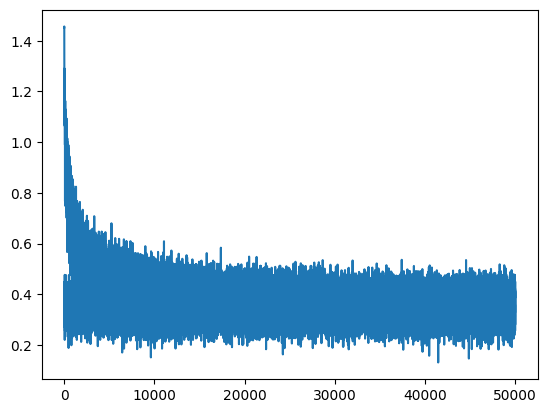

In [272]:
plt.plot(stepi,lossi)

In [273]:
print(loss.item())

2.4461121559143066


In [274]:
emb = C[Xdev] #32,3,2
h = torch.tanh(emb.view(-1,30) @ W1 + b1) #32,100
logits = h @ W2 + b2 # 32,27 
#counts = logits.exp()
#prob = counts/counts.sum(1,keepdims=True)
#loss = -prob[torch.arange(32),Y].log().mean()
loss = F.cross_entropy(logits,Ydev)
loss

tensor(2.2259, grad_fn=<NllLossBackward0>)

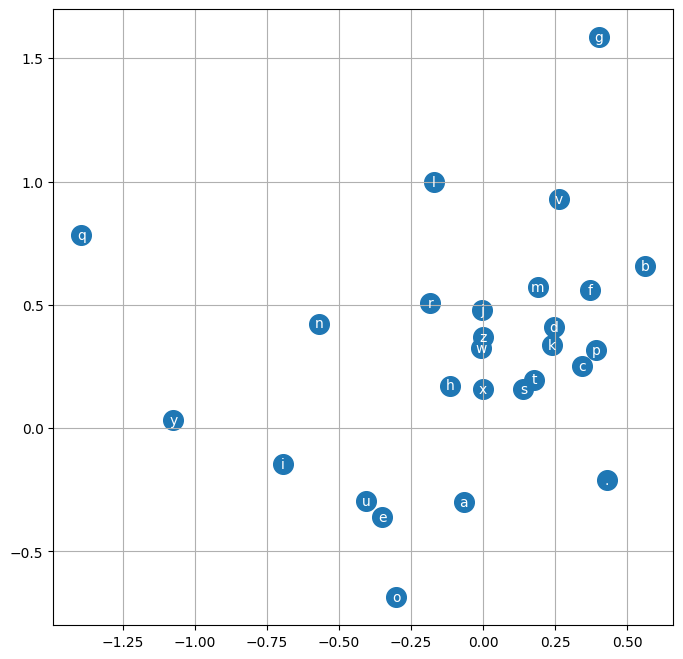

In [260]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [276]:

# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carmah.
amoricki.
kimri.
rehty.
salessa.
jazonel.
den.
rha.
kaqhiun.
kasia.
chaiiv.
kaleig.
dham.
jore.
quintis.
lin.
alian.
quiquelogiearyxi.
fine.
pirsa.
